In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:

from sklearn.model_selection import GroupShuffleSplit

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "UCI HAR Dataset"

ACTIVITIES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

def load_split(split):
    signal_dir = DATA_ROOT / split / "Inertial Signals"

    axes = ["x", "y", "z"]
    signals = [
        np.loadtxt(
            signal_dir / f"total_acc_{axis}_{split}.txt",
            dtype=np.float32,
        )
        for axis in axes
    ]

    X = np.stack(signals, axis=-1)
    y = np.loadtxt(
        DATA_ROOT / split / f"y_{split}.txt",
        dtype=np.int64,
    ) - 1

    subjects = np.loadtxt(
        DATA_ROOT / split / f"subject_{split}.txt",
        dtype=np.int64,
    )

    return X, y, subjects


X_train, y_train, subjects_train = load_split("train")
X_test, y_test, subjects_test = load_split("test")

print("Training:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
print("Training subjects:", np.unique(subjects_train))
print("Test subjects:", np.unique(subjects_test))

assert X_train.shape == (7352, 128, 3)
assert X_test.shape == (2947, 128, 3)
assert set(np.unique(subjects_train)).isdisjoint(
    set(np.unique(subjects_test))
)

print("Dataset and subject-split checks passed.")


Training: (7352, 128, 3) (7352,)
Test: (2947, 128, 3) (2947,)
Training subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test subjects: [ 2  4  9 10 12 13 18 20 24]
Dataset and subject-split checks passed.


In [3]:

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED,
)

train_idx, val_idx = next(
    splitter.split(X_train, y_train, groups=subjects_train)
)

X_tr = X_train[train_idx]
y_tr = y_train[train_idx]

X_val = X_train[val_idx]
y_val = y_train[val_idx]

groups_tr = subjects_train[train_idx]
groups_val = subjects_train[val_idx]

print("Model training windows:", X_tr.shape)
print("Validation windows:", X_val.shape)
print("Training subjects:", np.unique(groups_tr))
print("Validation subjects:", np.unique(groups_val))

assert set(groups_tr).isdisjoint(set(groups_val))

print("\nTraining class counts:")
print(pd.Series(y_tr).value_counts().sort_index())

print("\nValidation class counts:")
print(pd.Series(y_val).value_counts().sort_index())


Model training windows: (5551, 128, 3)
Validation windows: (1801, 128, 3)
Training subjects: [ 5  6  7  8 11 14 16 17 19 21 22 23 26 28 29 30]
Validation subjects: [ 1  3 15 25 27]

Training class counts:
0     888
1     797
2     744
3     993
4    1053
5    1076
Name: count, dtype: int64

Validation class counts:
0    338
1    276
2    242
3    293
4    321
5    331
Name: count, dtype: int64


In [4]:

axis_mean = X_tr.mean(axis=(0, 1), keepdims=True)
axis_std = X_tr.std(axis=(0, 1), keepdims=True)

axis_std = np.maximum(axis_std, 1e-6)

X_tr_norm = ((X_tr - axis_mean) / axis_std).astype(np.float32)
X_val_norm = ((X_val - axis_mean) / axis_std).astype(np.float32)
X_test_norm = ((X_test - axis_mean) / axis_std).astype(np.float32)

print("Input shape:", X_tr_norm.shape[1:])
print("Training mean by axis:", X_tr_norm.mean(axis=(0, 1)))
print("Training std by axis:", X_tr_norm.std(axis=(0, 1)))


Input shape: (128, 3)
Training mean by axis: [ 1.8561698e-04 -1.2228611e-06 -1.1708513e-06]
Training std by axis: [1.0000775  0.9999884  0.99996865]


In [5]:

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(128, 3), name="accelerometer_window"),

    layers.Conv1D(
        filters=16,
        kernel_size=5,
        padding="same",
        activation="relu",
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(
        filters=24,
        kernel_size=5,
        padding="same",
        activation="relu",
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.GlobalAveragePooling1D(),

    layers.Dense(16, activation="relu"),
    layers.Dense(6, activation="softmax"),
], name="tiny_har_cnn")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

print("Total parameters:", model.count_params())


Model: "tiny_har_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 16)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 24)         │         1,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 24)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 24)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,702 (10.55 KB)

 Trainable params: 2,702 (10.55 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 2702


In [6]:

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
]

history = model.fit(
    X_tr_norm,
    y_tr,
    validation_data=(X_val_norm, y_val),
    epochs=100,
    batch_size=64,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4747 - loss: 1.3001 - val_accuracy: 0.6902 - val_loss: 1.0194
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7411 - loss: 0.7570 - val_accuracy: 0.7934 - val_loss: 0.6172
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8152 - loss: 0.4903 - val_accuracy: 0.8384 - val_loss: 0.4470
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8402 - loss: 0.3859 - val_accuracy: 0.8662 - val_loss: 0.3709
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8580 - loss: 0.3293 - val_accuracy: 0.8795 - val_loss: 0.3256
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8699 - loss: 0.2941 - val_accuracy: 0.8884 - val_loss: 0.2996
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8786 - loss: 0.2706 - val_accuracy: 0.8873 - val_loss: 0.2870
Epoch 8/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8856 - loss: 0.2524 - val_accuracy: 0.8845 - v

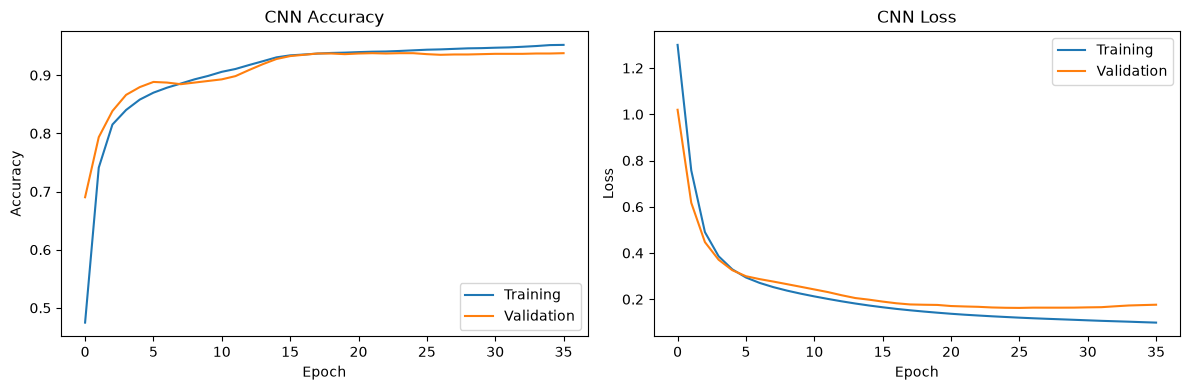

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


Test accuracy: 0.8558 (85.58%)
Test macro-F1: 0.8564
Parameters: 2,702
Batch inference time: 0.4675 seconds
Average laptop inference: 0.159 ms/window

Classification report:
                    precision    recall  f1-score   support

           WALKING     0.8394    0.9274    0.8812       496
  WALKING_UPSTAIRS     0.7563    0.8301    0.7915       471
WALKING_DOWNSTAIRS     1.0000    0.9071    0.9513       420
           SITTING     0.8019    0.7006    0.7478       491
          STANDING     0.7645    0.7688    0.7666       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.8558      2947
         macro avg     0.8603    0.8557    0.8564      2947
      weighted avg     0.8585    0.8558    0.8556      2947



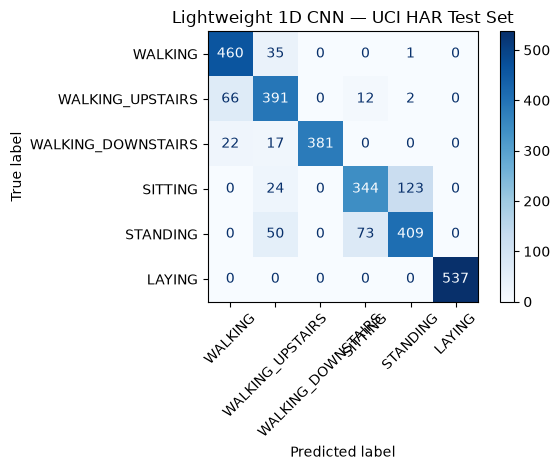

In [8]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import time

start = time.perf_counter()
test_probabilities = model.predict(
    X_test_norm,
    batch_size=64,
    verbose=0,
)
test_inference_s = time.perf_counter() - start

y_pred_cnn = np.argmax(test_probabilities, axis=1)

cnn_accuracy = accuracy_score(y_test, y_pred_cnn)
cnn_macro_f1 = f1_score(
    y_test, y_pred_cnn, average="macro"
)

print(f"Test accuracy: {cnn_accuracy:.4f} ({cnn_accuracy * 100:.2f}%)")
print(f"Test macro-F1: {cnn_macro_f1:.4f}")
print(f"Parameters: {model.count_params():,}")
print(f"Batch inference time: {test_inference_s:.4f} seconds")
print(
    "Average laptop inference: "
    f"{test_inference_s / len(y_test) * 1000:.3f} ms/window"
)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_cnn,
    labels=list(range(6)),
    target_names=ACTIVITIES,
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred_cnn, labels=list(range(6)))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ACTIVITIES,
).plot(cmap="Blues", xticks_rotation=45, values_format="d")

plt.title("Lightweight 1D CNN — UCI HAR Test Set")
plt.tight_layout()
plt.show()


In [9]:

MODEL_DIR = PROJECT_ROOT / "model"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "har_cnn_float32.keras"
model.save(model_path)

np.savez(
    MODEL_DIR / "normalization.npz",
    mean=axis_mean,
    std=axis_std,
)

cnn_results = pd.DataFrame([{
    "model": "Lightweight 1D CNN",
    "input": "(128, 3) normalized accelerometer",
    "accuracy": cnn_accuracy,
    "macro_f1": cnn_macro_f1,
    "parameters": model.count_params(),
    "model_size_bytes": model_path.stat().st_size,
    "laptop_inference_ms_per_window": (
        test_inference_s / len(y_test) * 1000
    ),
    "n_test_windows": len(y_test),
}])

cnn_results.to_csv(
    RESULTS_DIR / "cnn_float32_baseline.csv",
    index=False,
)

display(cnn_results)
print("Saved model:", model_path)


,model,input,accuracy,macro_f1,parameters,model_size_bytes,laptop_inference_ms_per_window,n_test_windows
0,Lightweight 1D CNN,"(128, 3) normalized accelerometer",0.855786,0.856416,2702,69995,0.158636,2947


Saved model: c:\Users\nandi\OneDrive\Desktop\tinyml-har-esp32\model\har_cnn_float32.keras
